In [2]:
import os
import re
import gc
import json
import warnings

from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.05
)

PALETTE = [
    "#4361EE",
    "#7209B7",
    "#F72585",
    "#4CC9F0",
    "#4895EF",
    "#F9C74F",
    "#43AA8B",
    "#F9844A"
]

plt.rcParams.update({
    "figure.figsize": (12, 6),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.titlesize": 15,
    "axes.labelsize": 12,
    "axes.titleweight": "bold",
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.25,
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

DATA_PATH = Path(
    r"E:\Work\AI\MAKTAB\HW-CW-S02\NLP Project\digikala-comments.csv"
)

CHUNK_SIZE = 100_000
RANDOM_SEED = 2026

np.random.seed(RANDOM_SEED)

RATING_BANDS = {
    "low": (0, 2.5),
    "medium": (2.5, 4.0),
    "high": (4.0, 5.0)
}

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}"
    )

FILE_SIZE_MB = DATA_PATH.stat().st_size / (1024 ** 2)

print("=" * 65)
print("DIGIKALA DESCRIPTIVE ANALYSIS")
print("=" * 65)

print(f"Dataset path : {DATA_PATH}")
print(f"File size    : {FILE_SIZE_MB:,.2f} MB")
print(f"Chunk size   : {CHUNK_SIZE:,}")
print(f"Random seed  : {RANDOM_SEED:,}")

print("\nConfiguration completed successfully.")

DIGIKALA DESCRIPTIVE ANALYSIS
Dataset path : E:\Work\AI\MAKTAB\HW-CW-S02\NLP Project\digikala-comments.csv
File size    : 1,219.30 MB
Chunk size   : 100,000
Random seed  : 2,026

Configuration completed successfully.


In [3]:
df_sample = pd.read_csv(
    DATA_PATH,
    nrows=1000,
    low_memory=False
)

print("Dataset columns:")
print("-" * 50)

for i, column in enumerate(df_sample.columns, start=1):
    print(f"{i:02d}. {column}")

print("\nSample shape:", df_sample.shape)

print("\nData types:")
display(
    df_sample.dtypes.astype(str).to_frame("Data Type")
)

REQUIRED_COLUMNS = [
    "id",
    "body",
    "rate",
    "recommendation_status",
    "product_id"
]

missing_columns = [
    col for col in REQUIRED_COLUMNS
    if col not in df_sample.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

OPTIONAL_COLUMNS = [
    "title",
    "created_at",
    "is_buyer",
    "likes",
    "dislikes",
    "seller_title",
    "seller_code",
    "advantages",
    "disadvantages",
    "true_to_size_rate"
]

available_optional_columns = [
    col for col in OPTIONAL_COLUMNS
    if col in df_sample.columns
]

print("\nAvailable optional columns:")
print(available_optional_columns)

preview_columns = [
    col for col in [
        "id",
        "body",
        "rate",
        "recommendation_status",
        "product_id"
    ]
    if col in df_sample.columns
]

display(df_sample[preview_columns].head(10))

print("\nSchema inspection completed.")

Dataset columns:
--------------------------------------------------
01. id
02. title
03. body
04. created_at
05. rate
06. recommendation_status
07. is_buyer
08. product_id
09. advantages
10. disadvantages
11. likes
12. dislikes
13. seller_title
14. seller_code
15. true_to_size_rate

Sample shape: (1000, 15)

Data types:


,Data Type
id,int64
title,object
body,object
created_at,object
rate,float64
recommendation_status,object
is_buyer,bool
product_id,int64
advantages,object
disadvantages,object



Available optional columns:
['title', 'created_at', 'is_buyer', 'likes', 'dislikes', 'seller_title', 'seller_code', 'advantages', 'disadvantages', 'true_to_size_rate']


,id,body,rate,recommendation_status,product_id
0,53672599,به درد نمیخوره,1.0,not_recommended,252058
1,9897229,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,0.0,recommended,252058
2,38074516,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خ...,0.0,recommended,3331597
3,18628562,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...,0.0,recommended,3331329
4,53301258,معمولیه اگه واسه خونه رنگ کردن شخصی میخواین او...,3.0,recommended,3255700
5,53266157,قبلا هم استفاده کردم اگه بلد باشین کار کردن با...,5.0,recommended,3305270
6,46206235,خوبه,2.0,NaN,3480048
7,40597171,خیلی به کارتون میاد قیمتشم مناسبه,5.0,recommended,3480048
8,46198656,دقیقا مطابق عکس بود,5.0,recommended,7626372
9,46901811,برا حالت دادن با اسپری یا پودر عالیه,5.0,recommended,821812



Schema inspection completed.


In [4]:
from collections import Counter
from tqdm.auto import tqdm

total_rows = 0
missing_counts = Counter()
product_counts = Counter()
unique_products = set()
unique_sellers = set()

recommendation_counts = Counter()
rating_counts = Counter()

column_names = None
dtype_info = {}

for chunk in tqdm(
    pd.read_csv(DATA_PATH, chunksize=CHUNK_SIZE, low_memory=False),
    desc="Scanning dataset"
):
    total_rows += len(chunk)

    if column_names is None:
        column_names = chunk.columns.tolist()
        dtype_info = chunk.dtypes.astype(str).to_dict()

    missing_counts.update(chunk.isna().sum().to_dict())

    if "product_id" in chunk.columns:
        product_values = chunk["product_id"].dropna()
        unique_products.update(product_values.unique())
        product_counts.update(product_values.value_counts().to_dict())

    if "seller_code" in chunk.columns:
        unique_sellers.update(chunk["seller_code"].dropna().unique())

    if "recommendation_status" in chunk.columns:
        recommendation_counts.update(
            chunk["recommendation_status"]
            .fillna("<MISSING>")
            .astype(str)
            .value_counts()
            .to_dict()
        )

    if "rate" in chunk.columns:
        rating_counts.update(
            chunk["rate"]
            .fillna("<MISSING>")
            .astype(str)
            .value_counts()
            .to_dict()
        )

dataset_summary = pd.DataFrame({
    "Metric": [
        "Total records",
        "Number of columns",
        "Unique products",
        "Unique sellers",
        "File size (MB)"
    ],
    "Value": [
        total_rows,
        len(column_names),
        len(unique_products),
        len(unique_sellers),
        round(Path(DATA_PATH).stat().st_size / (1024 ** 2), 2)
    ]
})

display(dataset_summary)

print("Dataset columns:")
display(pd.DataFrame({
    "Column": column_names,
    "Data type": [dtype_info[col] for col in column_names]
}))

missing_summary = pd.DataFrame({
    "Missing Count": pd.Series(missing_counts),
    "Missing Percentage": (
        pd.Series(missing_counts) / total_rows * 100
    )
}).sort_values("Missing Percentage", ascending=False)

display(missing_summary.style.background_gradient(
    cmap="YlOrRd",
    subset=["Missing Percentage"]
))

product_distribution = pd.Series(
    product_counts,
    name="Review Count"
).sort_values(ascending=False)

display(product_distribution.describe().to_frame("Reviews per Product"))

print(f"Total unique products: {len(unique_products):,}")
print(f"Total unique sellers: {len(unique_sellers):,}")

Scanning dataset: 0it [00:00, ?it/s]

,Metric,Value
0,Total records,6156289.0
1,Number of columns,15.0
2,Unique products,331599.0
3,Unique sellers,29213.0
4,File size (MB),1219.3


Dataset columns:


,Column,Data type
0,id,int64
1,title,object
2,body,object
3,created_at,object
4,rate,float64
5,recommendation_status,object
6,is_buyer,bool
7,product_id,int64
8,advantages,object
9,disadvantages,object


,Missing Count,Missing Percentage
true_to_size_rate,6065516,98.525524
disadvantages,5744017,93.303238
advantages,5448084,88.496235
title,2865062,46.538783
recommendation_status,894426,14.528655
seller_title,302181,4.908493
seller_code,302181,4.908493
body,637,0.010347
rate,0,0.000000
created_at,0,0.000000


,Reviews per Product
count,331599.000000
mean,18.565463
std,40.934097
min,1.000000
25%,1.000000
50%,4.000000
75%,13.000000
max,400.000000


Total unique products: 331,599
Total unique sellers: 29,213


,Missing Count,Missing Percentage,Non-Missing Count
true_to_size_rate,"6,065,516",98.53%,"90,773"
disadvantages,"5,744,017",93.30%,"412,272"
advantages,"5,448,084",88.50%,"708,205"
title,"2,865,062",46.54%,"3,291,227"
recommendation_status,"894,426",14.53%,"5,261,863"
seller_title,"302,181",4.91%,"5,854,108"
seller_code,"302,181",4.91%,"5,854,108"
body,637,0.01%,"6,155,652"
rate,0,0.00%,"6,156,289"
created_at,0,0.00%,"6,156,289"


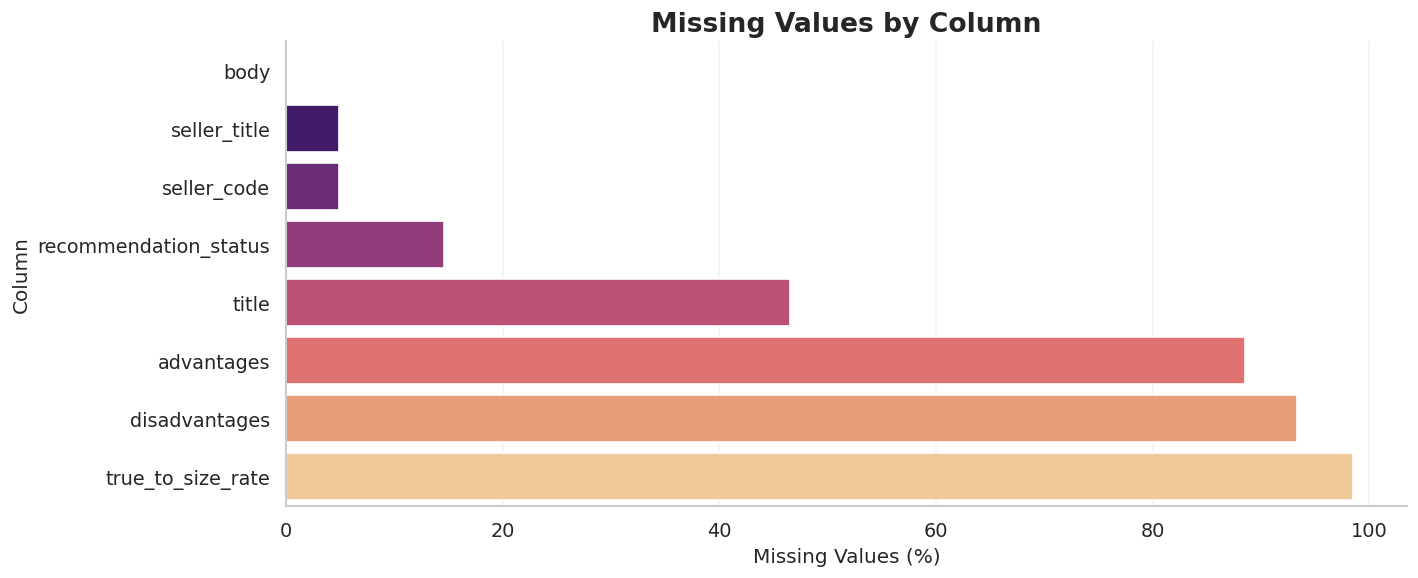

In [5]:
missing_summary = pd.DataFrame({
    "Missing Count": pd.Series(missing_counts),
    "Missing Percentage": pd.Series(missing_counts) / total_rows * 100,
    "Non-Missing Count": total_rows - pd.Series(missing_counts)
}).sort_values("Missing Percentage", ascending=False)

display(
    missing_summary.style
    .background_gradient(cmap="YlOrRd", subset=["Missing Percentage"])
    .format({
        "Missing Percentage": "{:.2f}%",
        "Missing Count": "{:,.0f}",
        "Non-Missing Count": "{:,.0f}"
    })
)

missing_columns = missing_summary[
    missing_summary["Missing Count"] > 0
].index.tolist()

fig, ax = plt.subplots(figsize=(12, max(5, len(missing_columns) * 0.35)))

if missing_columns:
    missing_plot = missing_summary.loc[missing_columns].sort_values(
        "Missing Percentage"
    )

    sns.barplot(
        x=missing_plot["Missing Percentage"],
        y=missing_plot.index,
        hue=missing_plot.index,
        palette="magma",
        legend=False,
        ax=ax
    )

    ax.set_title("Missing Values by Column", fontsize=16, fontweight="bold")
    ax.set_xlabel("Missing Values (%)")
    ax.set_ylabel("Column")
    ax.grid(axis="x", alpha=0.25)
else:
    ax.text(0.5, 0.5, "No missing values found",
            ha="center", va="center", fontsize=14)
    ax.set_axis_off()

plt.tight_layout()
plt.show()

In [6]:
missing_target_stats = []

for chunk in pd.read_csv(DATA_PATH, chunksize=CHUNK_SIZE, low_memory=False):
    if "recommendation_status" not in chunk.columns:
        continue

    target_missing = chunk["recommendation_status"].isna()

    for column in ["is_buyer", "rate", "product_id"]:
        if column in chunk.columns:
            grouped = (
                chunk.assign(target_missing=target_missing)
                .groupby(column, dropna=False)["target_missing"]
                .agg(["count", "sum"])
                .reset_index()
            )

            grouped["column"] = column
            missing_target_stats.append(grouped)

if missing_target_stats:
    missing_target_detail = pd.concat(
        missing_target_stats,
        ignore_index=True
    )

    for column in ["is_buyer", "rate", "product_id"]:
        subset = missing_target_detail[
            missing_target_detail["column"] == column
        ].copy()

        if not subset.empty:
            subset["missing_percentage"] = (
                subset["sum"] / subset["count"] * 100
            )

            if column == "product_id":
                subset = subset.sort_values(
                    "count", ascending=False
                ).head(20)

            print(f"\nMissing recommendation_status by {column}")

            display(
                subset.sort_values(
                    "missing_percentage", ascending=False
                ).head(30)
            )


Missing recommendation_status by is_buyer


,is_buyer,count,sum,column,rate,product_id,missing_percentage
0,False,4483,4483,is_buyer,NaN,NaN,100.0
10041,False,4238,4238,is_buyer,NaN,NaN,100.0
31488,False,4698,4698,is_buyer,NaN,NaN,100.0
19184,False,4714,4714,is_buyer,NaN,NaN,100.0
52533,False,4402,4402,is_buyer,NaN,NaN,100.0
40986,False,4251,4251,is_buyer,NaN,NaN,100.0
136668,False,4889,4889,is_buyer,NaN,NaN,100.0
125055,False,4692,4692,is_buyer,NaN,NaN,100.0
83337,False,4849,4849,is_buyer,NaN,NaN,100.0
92800,False,4652,4652,is_buyer,NaN,NaN,100.0



Missing recommendation_status by rate


,is_buyer,count,sum,column,rate,product_id,missing_percentage
83355,NaN,1,1,rate,1.15,NaN,100.0
379643,NaN,1,1,rate,1.64,NaN,100.0
455318,NaN,3,3,rate,3.45,NaN,100.0
429317,NaN,1,1,rate,0.65,NaN,100.0
429328,NaN,1,1,rate,1.29,NaN,100.0
429315,NaN,1,1,rate,0.57,NaN,100.0
348699,NaN,1,1,rate,0.90,NaN,100.0
455282,NaN,1,1,rate,1.67,NaN,100.0
105494,NaN,1,1,rate,4.56,NaN,100.0
441743,NaN,1,1,rate,0.35,NaN,100.0



Missing recommendation_status by product_id


,is_buyer,count,sum,column,rate,product_id,missing_percentage
447754,NaN,200,47,product_id,NaN,5699955.0,23.5
540674,NaN,200,45,product_id,NaN,2631628.0,22.5
447267,NaN,200,39,product_id,NaN,4638838.0,19.5
530855,NaN,200,35,product_id,NaN,2239447.0,17.5
540577,NaN,200,35,product_id,NaN,2415286.0,17.5
540646,NaN,200,33,product_id,NaN,2562966.0,16.5
530875,NaN,200,31,product_id,NaN,2299862.0,15.5
530796,NaN,200,30,product_id,NaN,2022469.0,15.0
530828,NaN,200,26,product_id,NaN,2150690.0,13.0
540698,NaN,200,25,product_id,NaN,2680664.0,12.5


,Count,Percentage
recommended,"4,162,839",67.62%
,"894,426",14.53%
no_idea,"594,121",9.65%
not_recommended,"504,903",8.20%


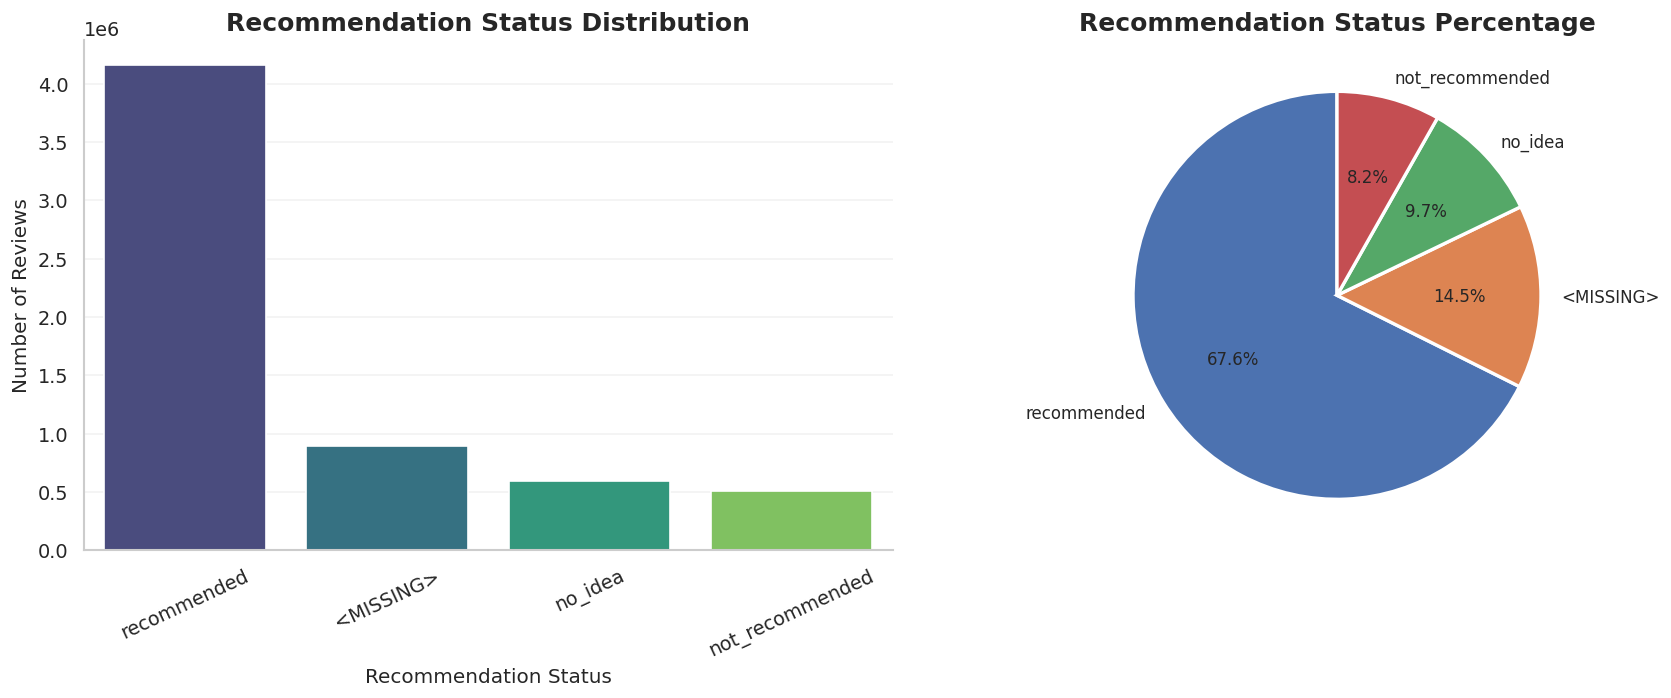

In [7]:
recommendation_counts = Counter()

for chunk in pd.read_csv(DATA_PATH, chunksize=CHUNK_SIZE, low_memory=False):
    if "recommendation_status" in chunk.columns:
        values = (
            chunk["recommendation_status"]
            .fillna("<MISSING>")
            .astype(str)
            .str.strip()
        )
        recommendation_counts.update(values.value_counts().to_dict())

recommendation_distribution = pd.DataFrame({
    "Count": pd.Series(recommendation_counts)
})

recommendation_distribution["Percentage"] = (
    recommendation_distribution["Count"] / total_rows * 100
)

recommendation_distribution = recommendation_distribution.sort_values(
    "Count", ascending=False
)

display(
    recommendation_distribution.style
    .background_gradient(cmap="Blues", subset=["Count"])
    .format({
        "Count": "{:,.0f}",
        "Percentage": "{:.2f}%"
    })
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(
    data=recommendation_distribution.reset_index(names="Class"),
    x="Class",
    y="Count",
    hue="Class",
    palette="viridis",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Recommendation Status Distribution", fontsize=15, fontweight="bold")
axes[0].set_xlabel("Recommendation Status")
axes[0].set_ylabel("Number of Reviews")
axes[0].tick_params(axis="x", rotation=25)

axes[1].pie(
    recommendation_distribution["Count"],
    labels=recommendation_distribution.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 10}
)

axes[1].set_title("Recommendation Status Percentage", fontsize=15, fontweight="bold")

plt.tight_layout()
plt.show()

,Metric,Value
0,Count,6156289.000
1,Minimum,0.000
2,Maximum,2500.000
3,Mean,3.648
4,Median,4.000
5,Standard Deviation,1.862
6,25th Percentile,3.000
7,50th Percentile,4.000
8,75th Percentile,5.000
9,90th Percentile,5.000


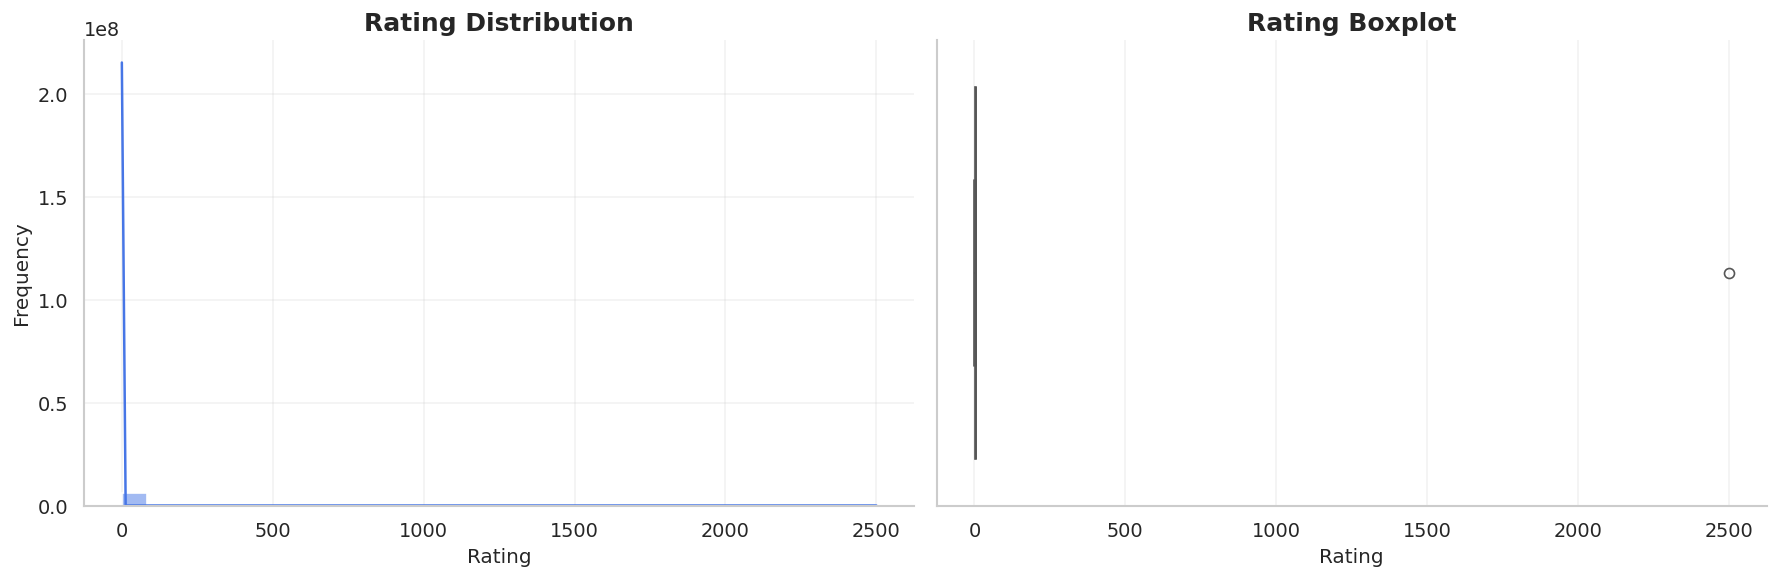

In [8]:
rate_values = []

rate_stats = {
    "count": 0,
    "sum": 0.0,
    "sum_squared": 0.0,
    "min": float("inf"),
    "max": float("-inf")
}

rate_quantile_chunks = []

for chunk in pd.read_csv(DATA_PATH, chunksize=CHUNK_SIZE, low_memory=False):
    if "rate" not in chunk.columns:
        continue

    rates = pd.to_numeric(chunk["rate"], errors="coerce")
    valid_rates = rates.dropna()

    rate_stats["count"] += len(valid_rates)
    rate_stats["sum"] += valid_rates.sum()
    rate_stats["sum_squared"] += (valid_rates ** 2).sum()

    if not valid_rates.empty:
        rate_stats["min"] = min(rate_stats["min"], valid_rates.min())
        rate_stats["max"] = max(rate_stats["max"], valid_rates.max())

    rate_quantile_chunks.append(valid_rates.to_numpy())

all_rates = np.concatenate(rate_quantile_chunks)

rate_summary = pd.DataFrame({
    "Metric": [
        "Count",
        "Minimum",
        "Maximum",
        "Mean",
        "Median",
        "Standard Deviation",
        "25th Percentile",
        "50th Percentile",
        "75th Percentile",
        "90th Percentile",
        "95th Percentile"
    ],
    "Value": [
        rate_stats["count"],
        rate_stats["min"],
        rate_stats["max"],
        rate_stats["sum"] / rate_stats["count"],
        np.median(all_rates),
        np.std(all_rates, ddof=1),
        np.percentile(all_rates, 25),
        np.percentile(all_rates, 50),
        np.percentile(all_rates, 75),
        np.percentile(all_rates, 90),
        np.percentile(all_rates, 95)
    ]
})

display(rate_summary.style.format({"Value": "{:.3f}"}))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    all_rates,
    bins=30,
    kde=True,
    color="#4776E6",
    ax=axes[0]
)

axes[0].set_title("Rating Distribution", fontsize=15, fontweight="bold")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Frequency")

sns.boxplot(
    x=all_rates,
    color="#F9A826",
    ax=axes[1]
)

axes[1].set_title("Rating Boxplot", fontsize=15, fontweight="bold")
axes[1].set_xlabel("Rating")

plt.tight_layout()
plt.show()

,Count,Percentage
high,4004905,65.053893
low,1092329,17.743306
medium,1059054,17.202801


Valid ratings: 6,156,288
Invalid non-missing ratings: 1


Rating Band,high,low,medium
Recommendation Status,,,
no_idea,101844,104215,388062
not_recommended,12635,424398,67870
recommended,3207921,463002,491915


Rating Band,high,low,medium
Recommendation Status,,,
no_idea,17.14%,17.54%,65.32%
not_recommended,2.50%,84.06%,13.44%
recommended,77.06%,11.12%,11.82%


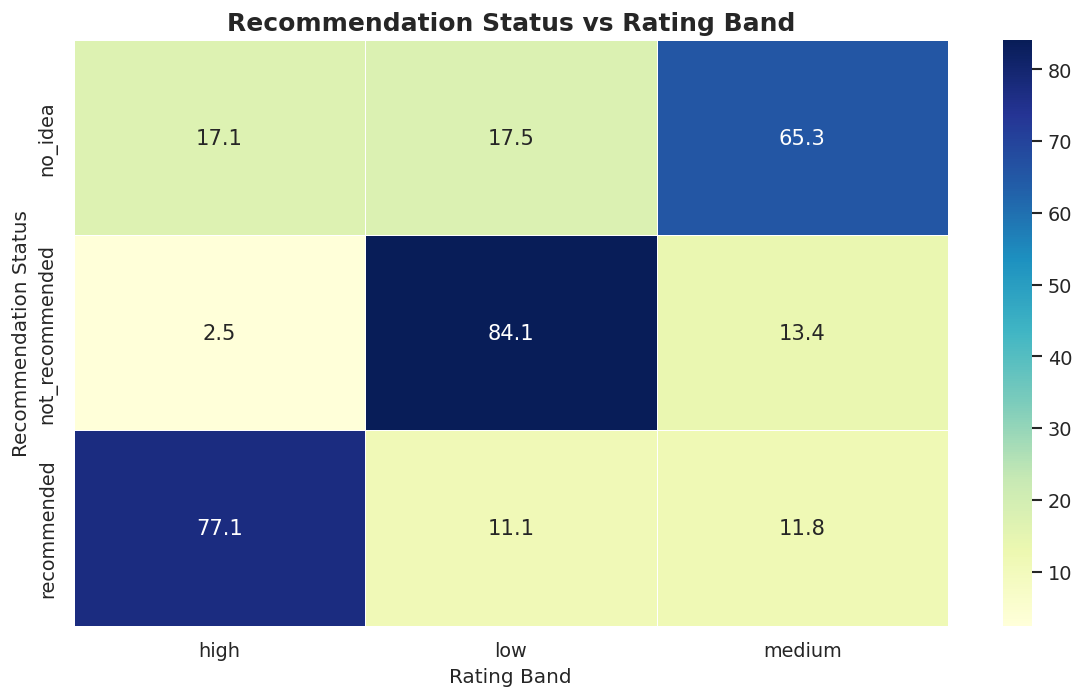

In [9]:
rating_band_counts = Counter()
rate_recommendation_stats = Counter()
invalid_rate_count = 0
valid_rate_count = 0

for chunk in pd.read_csv(DATA_PATH, chunksize=CHUNK_SIZE, low_memory=False):
    rates = pd.to_numeric(chunk["rate"], errors="coerce")

    valid_mask = rates.between(0, 5, inclusive="both")
    invalid_rate_count += int((~valid_mask & rates.notna()).sum())
    valid_rate_count += int(valid_mask.sum())

    bands = pd.cut(
        rates,
        bins=[-0.001, 2.5, 4.0, 5.0],
        labels=["low", "medium", "high"],
        right=False,
        include_lowest=True
    )

    bands.loc[rates.eq(5.0)] = "high"

    rating_band_counts.update(
        bands.dropna().astype(str).value_counts().to_dict()
    )

    if "recommendation_status" in chunk.columns:
        temp = pd.DataFrame({
            "recommendation_status": chunk["recommendation_status"],
            "rating_band": bands
        }).dropna()

        rate_recommendation_stats.update(
            (
                str(row.recommendation_status),
                str(row.rating_band)
            )
            for row in temp.itertuples(index=False)
        )

rating_band_summary = pd.DataFrame({
    "Count": pd.Series(rating_band_counts)
})

rating_band_summary["Percentage"] = (
    rating_band_summary["Count"] / rating_band_summary["Count"].sum() * 100
)

display(rating_band_summary)

print(f"Valid ratings: {valid_rate_count:,}")
print(f"Invalid non-missing ratings: {invalid_rate_count:,}")

rate_recommendation_table = pd.DataFrame(
    [
        {
            "Recommendation Status": key[0],
            "Rating Band": key[1],
            "Count": value
        }
        for key, value in rate_recommendation_stats.items()
    ]
)

rate_recommendation_pivot = rate_recommendation_table.pivot(
    index="Recommendation Status",
    columns="Rating Band",
    values="Count"
).fillna(0)

display(rate_recommendation_pivot)

rate_recommendation_percent = (
    rate_recommendation_pivot.div(
        rate_recommendation_pivot.sum(axis=1),
        axis=0
    ) * 100
)

display(rate_recommendation_percent.style.format("{:.2f}%"))

plt.figure(figsize=(10, 6))

sns.heatmap(
    rate_recommendation_percent,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Recommendation Status vs Rating Band", fontsize=15, fontweight="bold")
plt.xlabel("Rating Band")
plt.ylabel("Recommendation Status")
plt.tight_layout()
plt.show()

Analyzing text lengths: 0it [00:00, ?it/s]

,Metric,Value
0,Mean characters,48.39
1,Median characters,29.00
2,90th percentile characters,106.00
3,95th percentile characters,152.00
4,99th percentile characters,297.00
5,Maximum characters,"4,000.00"
6,Mean words,10.09
7,Median words,6.00
8,90th percentile words,22.00
9,95th percentile words,32.00


,count,sum,mean_char_length
not_recommended,504903,36988154,73.257941
no_idea,594121,35230143,59.297926
<MISSING>,894426,41509032,46.408570
recommended,4162839,184196080,44.247707


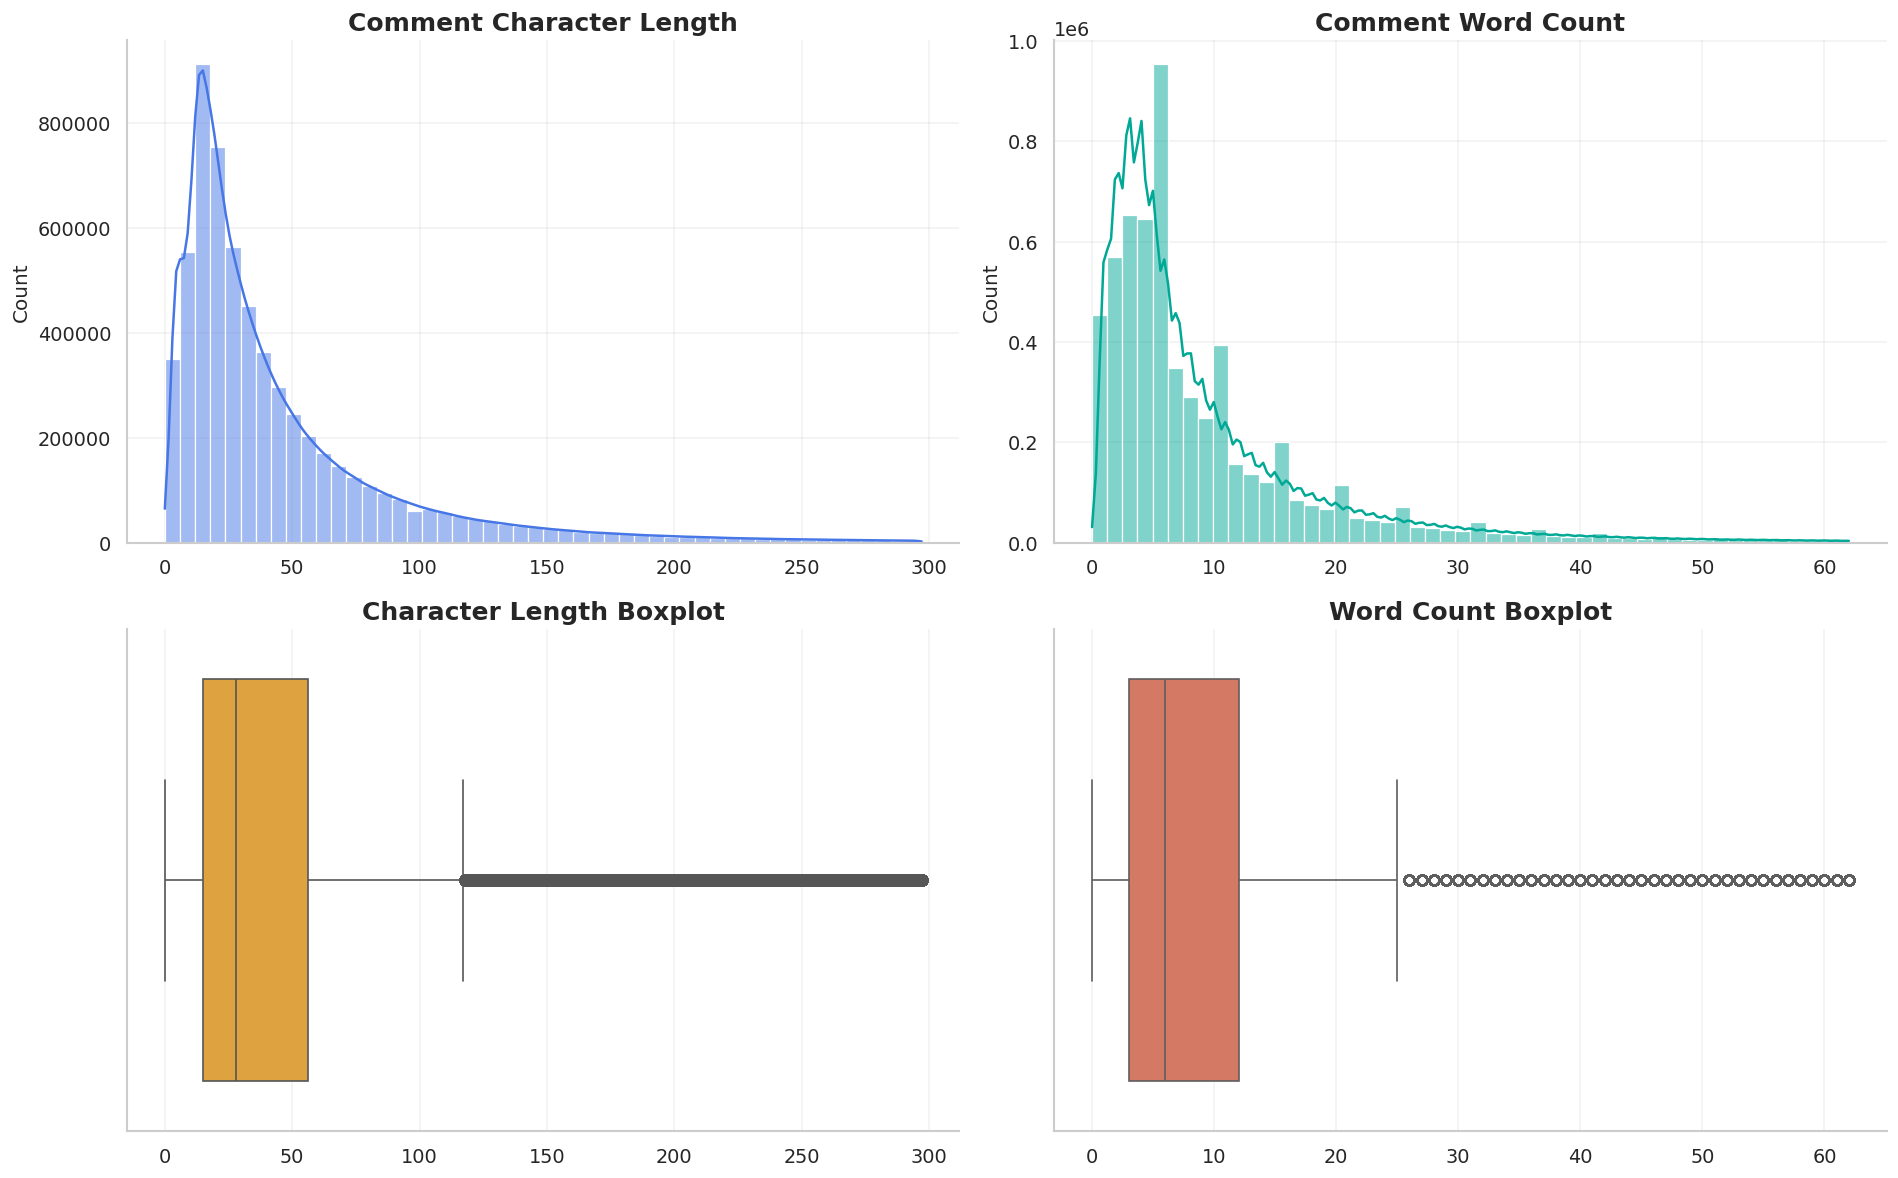

In [10]:
text_length_chunks = []
word_count_chunks = []
text_sample_chunks = []

length_by_class = {}

sample_limit = 200_000
sampled_count = 0

for chunk in tqdm(
    pd.read_csv(DATA_PATH, chunksize=CHUNK_SIZE, low_memory=False),
    desc="Analyzing text lengths"
):
    texts = chunk["body"].fillna("").astype(str)

    char_lengths = texts.str.len().to_numpy(dtype=np.int32)
    word_counts = texts.str.split().str.len().to_numpy(dtype=np.int32)

    text_length_chunks.append(char_lengths)
    word_count_chunks.append(word_counts)

    if "recommendation_status" in chunk.columns:
        temp = pd.DataFrame({
            "label": chunk["recommendation_status"].fillna("<MISSING>").astype(str),
            "char_length": char_lengths
        })

        grouped = temp.groupby("label")["char_length"].agg(
            ["count", "sum", "mean"]
        )

        for label, row in grouped.iterrows():
            if label not in length_by_class:
                length_by_class[label] = {
                    "count": 0,
                    "sum": 0
                }

            length_by_class[label]["count"] += int(row["count"])
            length_by_class[label]["sum"] += int(row["sum"])

    if sampled_count < sample_limit:
        remaining = sample_limit - sampled_count
        sampled = chunk.sample(
            n=min(remaining, len(chunk)),
            random_state=RANDOM_SEED
        )

        text_sample_chunks.append(
            sampled[["body"] + (
                ["recommendation_status"]
                if "recommendation_status" in sampled.columns
                else []
            )].copy()
        )

        sampled_count += len(sampled)

all_char_lengths = np.concatenate(text_length_chunks)
all_word_counts = np.concatenate(word_count_chunks)

text_length_summary = pd.DataFrame({
    "Metric": [
        "Mean characters",
        "Median characters",
        "90th percentile characters",
        "95th percentile characters",
        "99th percentile characters",
        "Maximum characters",
        "Mean words",
        "Median words",
        "90th percentile words",
        "95th percentile words",
        "99th percentile words",
        "Maximum words"
    ],
    "Value": [
        np.mean(all_char_lengths),
        np.median(all_char_lengths),
        np.percentile(all_char_lengths, 90),
        np.percentile(all_char_lengths, 95),
        np.percentile(all_char_lengths, 99),
        np.max(all_char_lengths),
        np.mean(all_word_counts),
        np.median(all_word_counts),
        np.percentile(all_word_counts, 90),
        np.percentile(all_word_counts, 95),
        np.percentile(all_word_counts, 99),
        np.max(all_word_counts)
    ]
})

display(text_length_summary.style.format({"Value": "{:,.2f}"}))

length_class_summary = pd.DataFrame.from_dict(
    length_by_class,
    orient="index"
)

length_class_summary["mean_char_length"] = (
    length_class_summary["sum"] / length_class_summary["count"]
)

display(
    length_class_summary.sort_values(
        "mean_char_length",
        ascending=False
    )
)

text_sample = pd.concat(text_sample_chunks, ignore_index=True)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

sns.histplot(
    all_char_lengths[all_char_lengths <= np.percentile(all_char_lengths, 99)],
    bins=50,
    kde=True,
    color="#4776E6",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Comment Character Length")

sns.histplot(
    all_word_counts[all_word_counts <= np.percentile(all_word_counts, 99)],
    bins=50,
    kde=True,
    color="#00A896",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Comment Word Count")

sns.boxplot(
    x=all_char_lengths[
        all_char_lengths <= np.percentile(all_char_lengths, 99)
    ],
    color="#F9A826",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Character Length Boxplot")

sns.boxplot(
    x=all_word_counts[
        all_word_counts <= np.percentile(all_word_counts, 99)
    ],
    color="#E76F51",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Word Count Boxplot")

plt.tight_layout()
plt.show()

In [11]:
import sqlite3
import hashlib
import os

duplicate_db_path = "descriptive_duplicates.sqlite"

if os.path.exists(duplicate_db_path):
    os.remove(duplicate_db_path)

connection = sqlite3.connect(duplicate_db_path)

connection.execute("""
CREATE TABLE review_ids (
    review_id TEXT PRIMARY KEY,
    occurrence_count INTEGER NOT NULL
)
""")

connection.execute("""
CREATE TABLE review_bodies (
    body_hash TEXT PRIMARY KEY,
    occurrence_count INTEGER NOT NULL,
    first_label TEXT,
    has_conflicting_labels INTEGER NOT NULL DEFAULT 0
)
""")

for chunk in tqdm(
    pd.read_csv(DATA_PATH, chunksize=CHUNK_SIZE, low_memory=False),
    desc="Checking duplicates"
):
    if "id" in chunk.columns:
        id_values = chunk["id"].dropna().astype(str).tolist()

        connection.executemany(
            """
            INSERT INTO review_ids (review_id, occurrence_count)
            VALUES (?, 1)
            ON CONFLICT(review_id)
            DO UPDATE SET occurrence_count = occurrence_count + 1
            """,
            [(value,) for value in id_values]
        )

    texts = chunk["body"].fillna("").astype(str)

    if "recommendation_status" in chunk.columns:
        labels = chunk["recommendation_status"].astype("string")
    else:
        labels = pd.Series([None] * len(chunk), index=chunk.index)

    body_records = []

    for body, label in zip(texts, labels):
        body_hash = hashlib.sha256(body.encode("utf-8")).hexdigest()
        label_value = None if pd.isna(label) else str(label)

        body_records.append((body_hash, label_value))

    connection.executemany(
        """
        INSERT INTO review_bodies (
            body_hash,
            occurrence_count,
            first_label,
            has_conflicting_labels
        )
        VALUES (?, 1, ?, 0)
        ON CONFLICT(body_hash)
        DO UPDATE SET
            occurrence_count = occurrence_count + 1,
            has_conflicting_labels =
                CASE
                    WHEN first_label IS NOT NULL
                     AND excluded.first_label IS NOT NULL
                     AND first_label != excluded.first_label
                    THEN 1
                    ELSE has_conflicting_labels
                END
        """,
        body_records
    )

    connection.commit()

duplicate_id_summary = pd.read_sql_query(
    """
    SELECT
        COUNT(*) AS unique_ids,
        SUM(CASE WHEN occurrence_count > 1 THEN 1 ELSE 0 END)
            AS duplicated_id_groups,
        SUM(CASE WHEN occurrence_count > 1 THEN occurrence_count - 1 ELSE 0 END)
            AS extra_rows_from_duplicate_ids
    FROM review_ids
    """,
    connection
)

duplicate_body_summary = pd.read_sql_query(
    """
    SELECT
        COUNT(*) AS unique_body_hashes,
        SUM(CASE WHEN occurrence_count > 1 THEN 1 ELSE 0 END)
            AS duplicated_body_groups,
        SUM(CASE WHEN occurrence_count > 1 THEN occurrence_count - 1 ELSE 0 END)
            AS extra_rows_from_duplicate_bodies,
        SUM(has_conflicting_labels) AS conflicting_label_groups
    FROM review_bodies
    """,
    connection
)

display(duplicate_id_summary)
display(duplicate_body_summary)

conflicting_body_examples = pd.read_sql_query(
    """
    SELECT body_hash, occurrence_count, first_label
    FROM review_bodies
    WHERE has_conflicting_labels = 1
    ORDER BY occurrence_count DESC
    LIMIT 20
    """,
    connection
)

display(conflicting_body_examples)

connection.close()

Checking duplicates: 0it [00:00, ?it/s]

,unique_ids,duplicated_id_groups,extra_rows_from_duplicate_ids
0,6153060,3226,3229


,unique_body_hashes,duplicated_body_groups,extra_rows_from_duplicate_bodies,conflicting_label_groups
0,4136258,197745,2020031,29448


,body_hash,occurrence_count,first_label
0,01fff4b387cb6493636e7c77fd0855c74e813ccbcdd812...,121349,recommended
1,2d09796ec3123723cf8edc0ac34d6d74a48599f03ed66d...,73854,recommended
2,056e4427b316f2c75e2b46f0a4648cfece744dc5462c67...,64297,recommended
3,c80d40c0b73ab4dd756c667edee8f289ac184961d31595...,23598,recommended
4,ab6927c023e3345a862ff737049785d616b44fd0f3d713...,19719,recommended
5,212f7a8891a0dcbb82442699a1da02f32448f0de7b9862...,13185,recommended
6,f70727b731633db7575c45be0d0e8f059b6736ee7d2933...,13130,recommended
7,759458b84c1ef2b1b33273789671b3dc7f8b7252a4537c...,11165,recommended
8,a1ffeee0f95ec371d181306b30fa78fe7bed3fb21a7632...,9681,recommended
9,ef45655e7b01d416b3807422d8424d044bd8ce6f9b1920...,8016,recommended


,Review Count,Cumulative Reviews,Cumulative Percentage
3331597,400,400,0.006497
4332510,400,800,0.012995
4095187,400,1200,0.019492
2156856,279,1479,0.024024
3392906,250,1729,0.028085
82098,238,1967,0.031951
4012333,233,2200,0.035736
5715766,233,2433,0.039521
7291752,232,2665,0.043289
4545846,221,2886,0.046879


,Metric,Value
0,Number of unique products,331599.000000
1,Reviews from top 20 products (%),0.082404
2,Reviews from top 1% products (%),10.846226
3,Average reviews per product,18.565463
4,Median reviews per product,4.000000
5,Maximum reviews for one product,400.000000


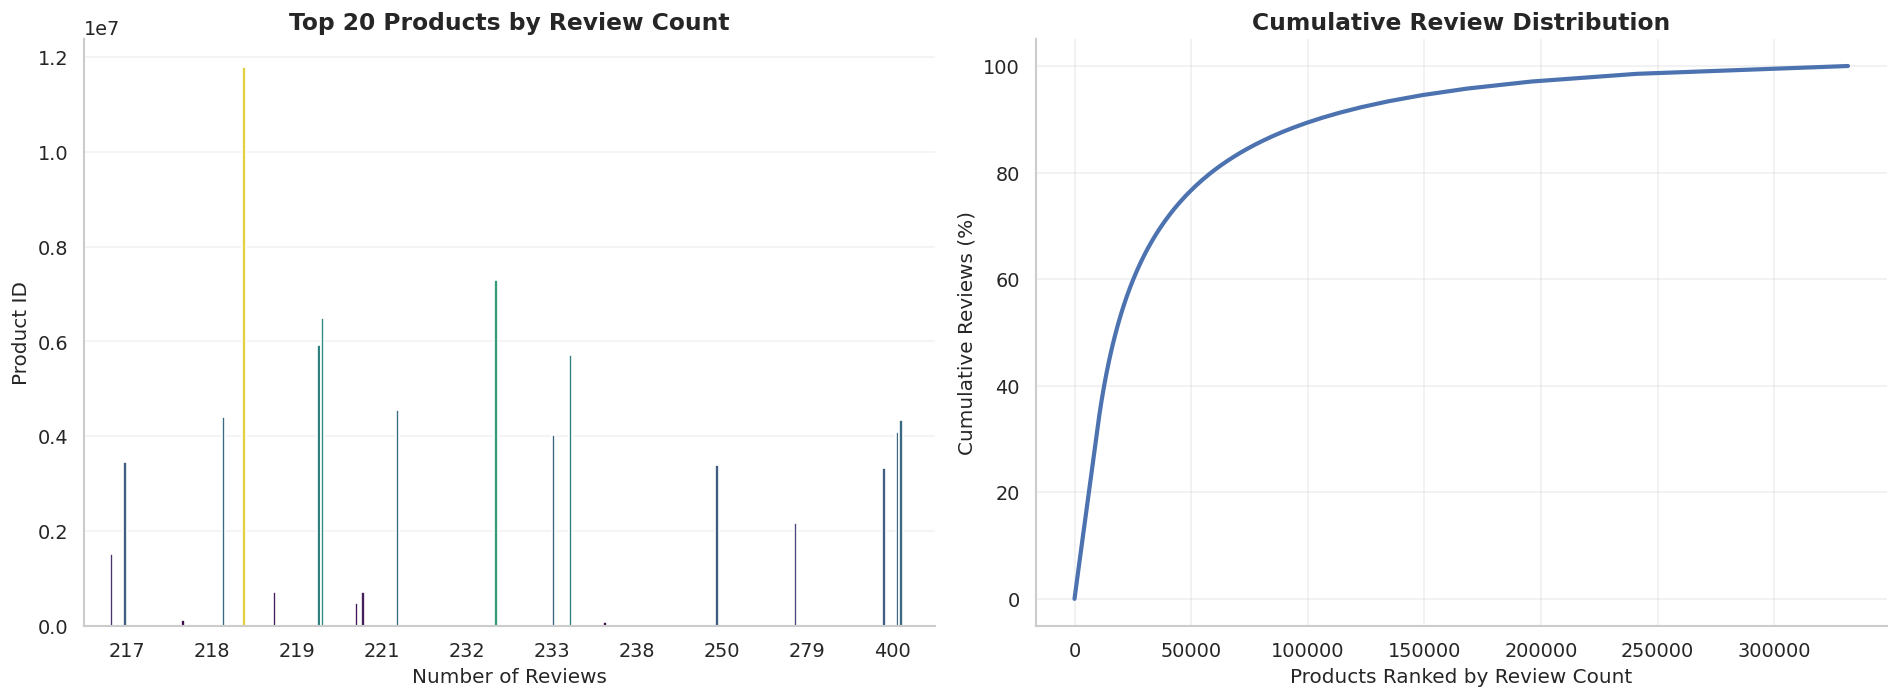

In [12]:
product_summary = pd.DataFrame({
    "Review Count": pd.Series(product_counts)
}).sort_values("Review Count", ascending=False)

product_summary["Cumulative Reviews"] = (
    product_summary["Review Count"].cumsum()
)

product_summary["Cumulative Percentage"] = (
    product_summary["Cumulative Reviews"] / total_rows * 100
)

top_products = product_summary.head(20).copy()

display(top_products)

top_product_share = (
    top_products["Review Count"].sum() / total_rows * 100
)

top_1_percent_count = max(
    1,
    int(len(product_summary) * 0.01)
)

top_1_percent_share = (
    product_summary.head(top_1_percent_count)["Review Count"].sum()
    / total_rows * 100
)

product_concentration_summary = pd.DataFrame({
    "Metric": [
        "Number of unique products",
        "Reviews from top 20 products (%)",
        "Reviews from top 1% products (%)",
        "Average reviews per product",
        "Median reviews per product",
        "Maximum reviews for one product"
    ],
    "Value": [
        len(product_summary),
        top_product_share,
        top_1_percent_share,
        product_summary["Review Count"].mean(),
        product_summary["Review Count"].median(),
        product_summary["Review Count"].max()
    ]
})

display(product_concentration_summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=top_products.reset_index(),
    x="Review Count",
    y="index",
    hue="index",
    palette="viridis",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Top 20 Products by Review Count", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Number of Reviews")
axes[0].set_ylabel("Product ID")

axes[1].plot(
    np.arange(1, len(product_summary) + 1),
    product_summary["Cumulative Percentage"],
    linewidth=2.5
)

axes[1].set_title("Cumulative Review Distribution", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Products Ranked by Review Count")
axes[1].set_ylabel("Cumulative Reviews (%)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Analyzing vocabulary: 0it [00:00, ?it/s]

,Word,Frequency
0,و,2755192
1,بود,1405447
2,خیلی,1350034
3,خوب,1106427
4,به,1076037
5,از,977096
6,خوبه,947950
7,که,866043
8,عالی,805276
9,من,779983


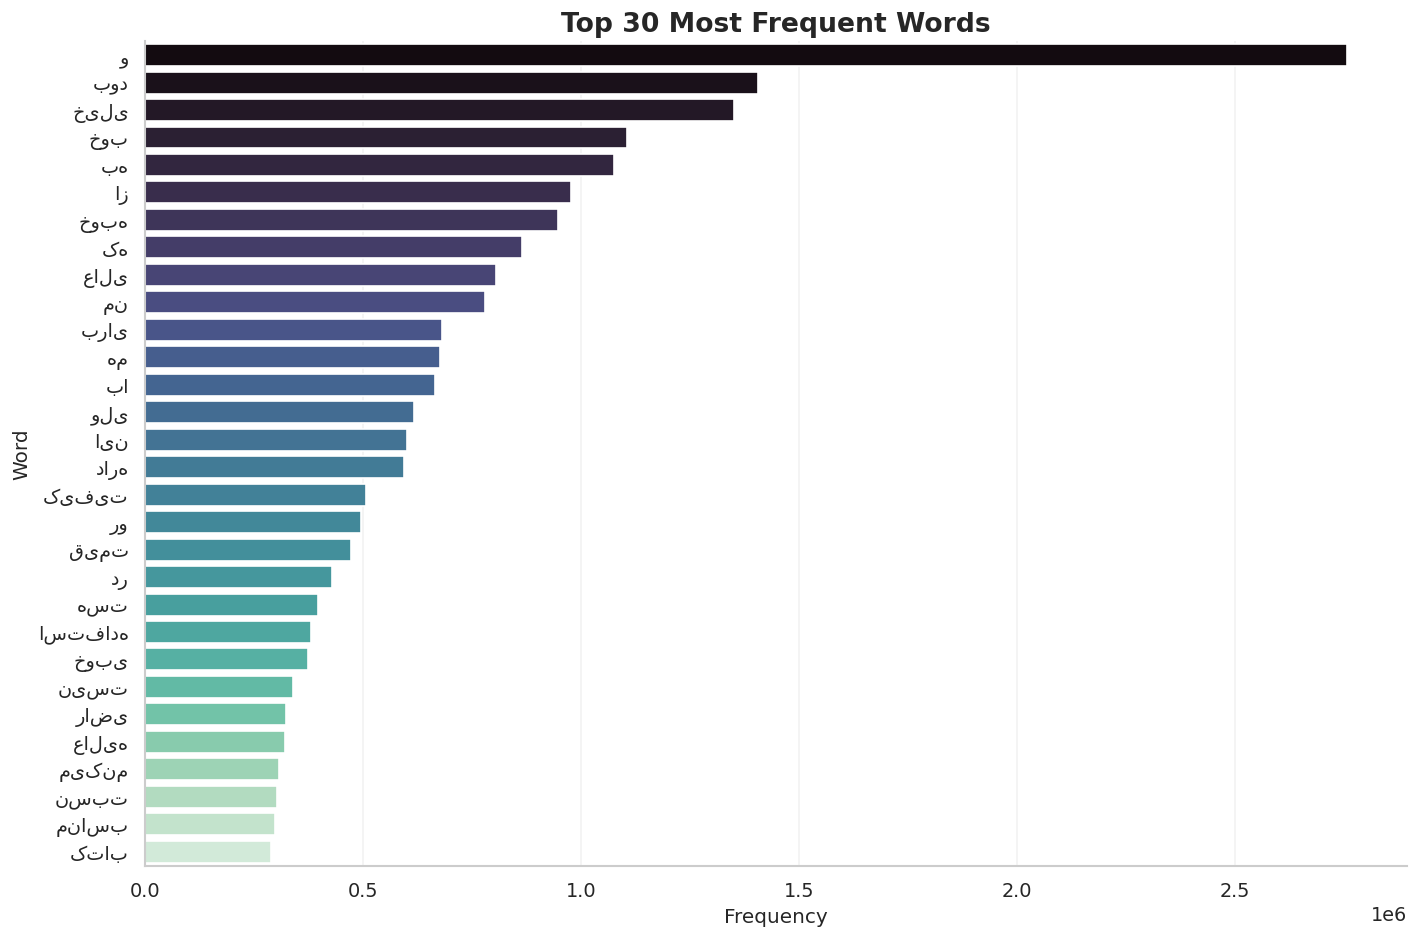

In [13]:
from collections import Counter
import re

word_counter = Counter()

for chunk in tqdm(
    pd.read_csv(DATA_PATH, chunksize=CHUNK_SIZE, low_memory=False),
    desc="Analyzing vocabulary"
):
    texts = chunk["body"].dropna().astype(str)

    for text_value in texts:
        words = re.findall(r"\w+", text_value.lower())
        word_counter.update(words)

top_words = pd.DataFrame(
    word_counter.most_common(30),
    columns=["Word", "Frequency"]
)

display(top_words)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_words,
    x="Frequency",
    y="Word",
    hue="Word",
    palette="mako",
    legend=False
)

plt.title("Top 30 Most Frequent Words", fontsize=16, fontweight="bold")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

In [14]:
output_dir = Path("descriptive_analysis_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

dataset_summary.to_csv(
    output_dir / "dataset_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

missing_summary.to_csv(
    output_dir / "missing_values_summary.csv",
    encoding="utf-8-sig"
)

recommendation_distribution.to_csv(
    output_dir / "recommendation_distribution.csv",
    encoding="utf-8-sig"
)

rate_summary.to_csv(
    output_dir / "rating_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

rating_band_summary.to_csv(
    output_dir / "rating_band_summary.csv",
    encoding="utf-8-sig"
)

rate_recommendation_pivot.to_csv(
    output_dir / "rating_recommendation_crosstab.csv",
    encoding="utf-8-sig"
)

text_length_summary.to_csv(
    output_dir / "text_length_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

length_class_summary.to_csv(
    output_dir / "text_length_by_class.csv",
    encoding="utf-8-sig"
)

product_summary.head(100).to_csv(
    output_dir / "top_100_products.csv",
    encoding="utf-8-sig"
)

top_words.to_csv(
    output_dir / "top_words.csv",
    index=False,
    encoding="utf-8-sig"
)

duplicate_id_summary.to_csv(
    output_dir / "duplicate_id_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

duplicate_body_summary.to_csv(
    output_dir / "duplicate_body_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print(f"Analysis tables saved to: {output_dir.resolve()}")

Analysis tables saved to: E:\Work\AI\MAKTAB\HW-CW-S02\NLP Project\descriptive_analysis_outputs


In [15]:
largest_missing_column = missing_summary["Missing Percentage"].idxmax()
largest_missing_percentage = missing_summary.loc[
    largest_missing_column,
    "Missing Percentage"
]

largest_class = recommendation_distribution["Count"].idxmax()
largest_class_percentage = recommendation_distribution.loc[
    largest_class,
    "Percentage"
]

median_char_length = np.median(all_char_lengths)
p95_char_length = np.percentile(all_char_lengths, 95)
p99_char_length = np.percentile(all_char_lengths, 99)

short_comments_percentage = (
    np.sum(all_char_lengths < 10) / len(all_char_lengths) * 100
)

long_comments_percentage = (
    np.sum(all_char_lengths > p95_char_length) / len(all_char_lengths) * 100
)

conclusions = [
    f"The dataset contains {total_rows:,} records and {len(column_names)} columns.",
    f"The dataset contains {len(unique_products):,} unique products.",
    f"The dataset contains {len(unique_sellers):,} unique sellers.",
    f"The column with the highest missing-value percentage is {largest_missing_column}, with {largest_missing_percentage:.2f}% missing values.",
    f"The most frequent recommendation class is {largest_class}, representing {largest_class_percentage:.2f}% of all records.",
    f"The median comment length is {median_char_length:.0f} characters.",
    f"The 95th percentile of comment length is {p95_char_length:.0f} characters.",
    f"The 99th percentile of comment length is {p99_char_length:.0f} characters.",
    f"{short_comments_percentage:.2f}% of comments contain fewer than 10 characters.",
    f"{long_comments_percentage:.2f}% of comments are longer than the 95th percentile threshold.",
    f"The top 20 products account for {top_product_share:.2f}% of all reviews.",
    f"The top 1% of products account for {top_1_percent_share:.2f}% of all reviews."
]

conclusions_df = pd.DataFrame({
    "Finding": conclusions
})

display(conclusions_df)

conclusions_df.to_csv(
    output_dir / "descriptive_analysis_conclusions.csv",
    index=False,
    encoding="utf-8-sig"
)

,Finding
0,"The dataset contains 6,156,289 records and 15 ..."
1,"The dataset contains 331,599 unique products."
2,"The dataset contains 29,213 unique sellers."
3,The column with the highest missing-value perc...
4,The most frequent recommendation class is reco...
5,The median comment length is 29 characters.
6,The 95th percentile of comment length is 152 c...
7,The 99th percentile of comment length is 297 c...
8,10.93% of comments contain fewer than 10 chara...
9,4.99% of comments are longer than the 95th per...
